# Natural Language Project Group 39

## 1. Load and structurally repair the files

The training data has occasional records split across physical lines. Join only the known overflow pattern (a line ending in `";;;` followed by a line that does not start a new known label), then parse each record independently. The unlabeled test file is parsed as four text columns and its physical line breaks are truncated, matching the supplied file's record convention.


In [85]:
import csv
import html
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion
from sklearn.svm import LinearSVC

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_columns', 20)

LABELS = {
    'Surgery', 'Cardiovascular-Pulmonary', 'Orthopedic', 'Radiology',
    'General Medicine', 'Gastroenterology', 'Neurology', 'Obstetrics-Gynecology',
    'Neurosurgery', 'Ophthalmology', 'Psychiatry-Psychology', 'Dermatology',
}
CLASS_ORDER = sorted(LABELS)
ALL_COLS = ['medical_specialty', 'description', 'sample_name', 'transcription', 'keywords']
TEXT_COLS = ALL_COLS[1:]
RECORD_START = re.compile(r'^(' + '|'.join(map(re.escape, LABELS)) + r');')


def load_train(path):
    with open(path, encoding='utf-8-sig', newline='') as source:
        lines = source.read().splitlines()
    records = [line for line in lines[1:] if line.strip()]
    repaired = []
    for line in records:
        continuation = repaired and repaired[-1].endswith('";;;') and not RECORD_START.match(line)
        if continuation:
            head = repaired.pop()[:-4]
            line = head + line.lstrip('"').rstrip('";') + ';'
        repaired.append(line)

    rows, bad_rows = [], []
    for row_number, record in enumerate(repaired):
        fields = next(csv.reader([record], delimiter=';'))
        if any(field.strip() for field in fields[len(ALL_COLS):]):
            bad_rows.append(row_number)
        fields = (fields + [''] * len(ALL_COLS))[:len(ALL_COLS)]
        rows.append([field.replace('""', '"').strip() for field in fields])

    frame = pd.DataFrame(rows, columns=ALL_COLS).replace('', pd.NA)
    if bad_rows:
        raise ValueError(f'Unexpected non-empty extra fields in repaired rows: {bad_rows[:10]}')
    return frame


def load_test(path):
    frame = pd.read_csv(path, sep=';', header=None, names=TEXT_COLS, encoding='utf-8-sig')
    for column in TEXT_COLS:
        frame[column] = frame[column].map(
            lambda value: str(value).splitlines()[0].strip() if pd.notna(value) else pd.NA
        )
    return frame


train_raw = load_train(Path('train.csv'))
test_raw = load_test(Path('test_no_labels.csv'))
print(f'Training rows: {len(train_raw):,}; test rows: {len(test_raw):,}')
print('Training labels recovered:', sorted(train_raw['medical_specialty'].dropna().unique()))
print('Unexpected labels:', sorted(set(train_raw['medical_specialty'].dropna()) - LABELS))


Training rows: 2,669; test rows: 398
Training labels recovered: ['Cardiovascular-Pulmonary', 'Dermatology', 'Gastroenterology', 'General Medicine', 'Neurology', 'Neurosurgery', 'Obstetrics-Gynecology', 'Ophthalmology', 'Orthopedic', 'Psychiatry-Psychology', 'Radiology', 'Surgery']
Unexpected labels: []


## 2. Understand the data before modeling

Check record counts, class balance, missingness, field lengths, representative cases, duplicates, and label conflicts. These checks matter because the most common class is much larger than several specialties, and identical reports can carry different labels.


In [86]:
print('Train shape:', train_raw.shape, '| test shape:', test_raw.shape)
print('Duplicate complete training rows:', int(train_raw.duplicated().sum()))
print('\nMissing values (training):')
print(train_raw.isna().sum().to_string())
print('\nMissing values (test):')
print(test_raw.isna().sum().to_string())

word_counts = pd.DataFrame({
    column: train_raw[column].fillna('').astype(str).str.split().str.len()
    for column in TEXT_COLS
})
length_summary = pd.DataFrame({
    'missing %': (train_raw[TEXT_COLS].isna().mean() * 100).round(1),
    'median words': word_counts.median().astype(int),
    'mean words': word_counts.mean().round(1),
    'max words': word_counts.max().astype(int),
})
print('\nText-field lengths:')
print(length_summary)


Train shape: (2669, 5) | test shape: (398, 4)
Duplicate complete training rows: 0

Missing values (training):
medical_specialty      0
description            1
sample_name            7
transcription         31
keywords             450

Missing values (test):
description       0
sample_name       0
transcription     2
keywords         72

Text-field lengths:
               missing %  median words  mean words  max words
description          0.0            16        18.9         76
sample_name          0.3             4         3.8          8
transcription        1.2           386       451.7       2454
keywords            16.9            19        22.6        118


                          records  share %
medical_specialty                         
Cardiovascular-Pulmonary      309     11.6
Dermatology                    25      0.9
Gastroenterology              195      7.3
General Medicine              212      7.9
Neurology                     184      6.9
Neurosurgery                   79      3.0
Obstetrics-Gynecology         136      5.1
Ophthalmology                  73      2.7
Orthopedic                    300     11.2
Psychiatry-Psychology          41      1.5
Radiology                     222      8.3
Surgery                       893     33.5

Largest/smallest class ratio: 35.7:1
Always-Surgery accuracy: 33.5%


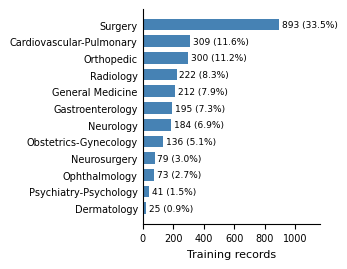

In [87]:
class_counts = train_raw['medical_specialty'].value_counts().reindex(CLASS_ORDER, fill_value=0)
class_summary = pd.DataFrame({
    'records': class_counts,
    'share %': (class_counts / len(train_raw) * 100).round(1),
})
print(class_summary.to_string())
print(f'\nLargest/smallest class ratio: {class_counts.max() / class_counts.min():.1f}:1')
print(f'Always-Surgery accuracy: {class_counts.max() / len(train_raw):.1%}')
# Compact horizontal bar chart sized for one column of a two-column report
sorted_counts = class_counts.sort_values()
fig, ax = plt.subplots(figsize=(3.4, 2.8))
bars = ax.barh(sorted_counts.index, sorted_counts.values, color='steelblue', height=0.7)
ax.bar_label(bars, labels=[f'{n} ({n / len(train_raw):.1%})' for n in sorted_counts.values],
             padding=2, fontsize=6.5)
ax.set_xlabel('Training records', fontsize=8)
ax.tick_params(axis='y', labelsize=7, length=0)
ax.tick_params(axis='x', labelsize=7)
ax.set_xlim(0, sorted_counts.max() * 1.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
#fig.savefig(FIG / 'class_distribution.pdf', bbox_inches='tight')
plt.show()


In [88]:
print('\nDuplicate-text conflicts:')
for column in ['description', 'sample_name', 'transcription']:
    subset = train_raw.dropna(subset=[column])
    grouped = subset.groupby(column)['medical_specialty']
    label_counts = grouped.nunique()
    conflicting = label_counts[label_counts > 1].index
    affected = int(grouped.size().reindex(conflicting).sum()) if len(conflicting) else 0
    print(f'{column}: {len(conflicting):,} repeated text values have multiple labels; {affected:,} rows affected')



Duplicate-text conflicts:
description: 736 repeated text values have multiple labels; 1,558 rows affected
sample_name: 741 repeated text values have multiple labels; 1,551 rows affected
transcription: 730 repeated text values have multiple labels; 1,528 rows affected


## 3. Audit the keyword field for target leakage

Before text cleaning, check whether a keyword list begins with an exact specialty name (including `obstetrics / gynecology`). This is suspicious because it directly encodes the answer. Keep the marker as a separate, explicitly disclosed rule for the supplied competition output; remove it from text features so the fallback model cannot learn from it. The marker-assisted validation score must not be interpreted as text-only generalization.


In [89]:
LABEL_FROM_PREFIX = {label.lower(): label for label in LABELS}
LABEL_FROM_PREFIX.update({label.lower().replace('-', ' / '): label for label in LABELS})


def marker_label(value):
    if pd.isna(value):
        return None
    first_term = str(value).split(',', 1)[0].strip().lower()
    return LABEL_FROM_PREFIX.get(first_term)


def label_marker(row):
    # Some malformed test rows have the keyword list shifted into description or transcription.
    for column in ['keywords', 'description', 'transcription']:
        marker = marker_label(row[column])
        if marker is not None:
            return marker
    return None


train_marker = train_raw.apply(label_marker, axis=1)
test_marker = test_raw.apply(label_marker, axis=1)
marker_rows = train_marker.notna()
marker_matches = int((train_marker[marker_rows] == train_raw.loc[marker_rows, 'medical_specialty']).sum())
marker_mismatches = int(marker_rows.sum()) - marker_matches
print(f'Train rows with exact specialty marker: {int(marker_rows.sum()):,}/{len(train_raw):,} ({marker_rows.mean():.1%})')
print(f'Markers matching their training labels: {marker_matches:,}; mismatches: {marker_mismatches:,}')
print(f'Test rows with exact marker in any text field: {int(test_marker.notna().sum()):,}/{len(test_raw):,} ({test_marker.notna().mean():.1%})')
print('Test marker locations:', {
    column: int(test_raw[column].fillna('').astype(str).str.match(
        r'^\s*(?:' + '|'.join(re.escape(x) for x in LABEL_FROM_PREFIX) + r')\s*,', case=False
    ).sum()) for column in ['keywords', 'description', 'transcription']
})
if marker_mismatches:
    raise ValueError('Specialty prefix does not match the training label; review the leakage rule.')


Train rows with exact specialty marker: 2,219/2,669 (83.1%)
Markers matching their training labels: 2,219; mismatches: 0
Test rows with exact marker in any text field: 320/398 (80.4%)
Test marker locations: {'keywords': 320, 'description': 0, 'transcription': 0}


## 4. Clean and normalize the text

In [90]:
# Match and remove a specialty label appearing at the start of a text field
PREFIX_PATTERN = re.compile(
    r'^\s*(?:' + '|'.join(re.escape(value) for value in sorted(LABEL_FROM_PREFIX, key=len, reverse=True)) + r')\s*,\s*',
    flags=re.IGNORECASE,
)
# Remove everything from "NOTE" onwards in the keywords field
DISCLAIMER_PATTERN = re.compile(r'NOTE\b.*$', flags=re.IGNORECASE | re.DOTALL)


def clean_text(value, column):
    # Replace missing values with an empty string
    if pd.isna(value):
        return ''
    # Normalize Unicode and decode HTML entities
    text = unicodedata.normalize('NFKC', html.unescape(str(value)))
    # Replace line breaks with spaces
    text = text.replace('\r', ' ').replace('\n', ' ')
    # Remove specialty prefixes from the beginning of the text
    #text = PREFIX_PATTERN.sub('', text)
    # Remove disclaimer text from the keywords field
    if column == 'keywords':
        text = DISCLAIMER_PATTERN.sub('', text)
    # Normalize whitespace and remove extra spaces/commas
    return re.sub(r'\s+', ' ', text).strip(' ,')


def clean_frame(frame):
    # Create a copy so the original data remains unchanged
    cleaned = frame.copy()
    # Clean each of the four text fields
    for column in TEXT_COLS:
        cleaned[column] = cleaned[column].map(lambda value: clean_text(value, column))
    return cleaned


def combine_fields(frame):
    # Combine all cleaned text fields into one document per record
    return frame[TEXT_COLS].fillna('').apply(
        lambda row: ' '.join(f'{column}: {row[column]}' for column in TEXT_COLS if row[column]),
        axis=1,
    )

# Apply the same preprocessing to training and test data
train_clean = clean_frame(train_raw)
test_clean = clean_frame(test_raw)
# Combine the four fields into a single text document
train_text = combine_fields(train_clean)
test_text = combine_fields(test_clean)


print('Clean train/test shapes:', train_clean.shape, test_clean.shape)
print('Empty combined training documents:', int(train_text.str.strip().eq('').sum()))
print('Marker text remaining in cleaned keywords:', int(train_clean['keywords'].fillna('').str.match(PREFIX_PATTERN).sum()))


Clean train/test shapes: (2669, 5) (398, 4)
Empty combined training documents: 0
Marker text remaining in cleaned keywords: 2210


## 5. Model training

## Validation split

In [91]:
X_train_idx, X_valid_idx = train_test_split(
    np.arange(len(train_clean)), test_size=0.1, random_state=42,
    stratify=train_clean['medical_specialty'],
)
y = train_clean['medical_specialty'].to_numpy()
y_valid = y[X_valid_idx]


def report_scores(name, truth, predicted):
    per_class = f1_score(truth, predicted, labels=CLASS_ORDER, average=None, zero_division=0)
    print(f'\n{name}')
    print(f'Accuracy: {accuracy_score(truth, predicted):.4f} | macro-F1: {f1_score(truth, predicted, average="macro"):.4f} | min class F1: {per_class.min():.4f}')
    print(classification_report(truth, predicted, labels=CLASS_ORDER, zero_division=0, digits=3))
    return per_class

## Baseline MultinomialNB + TF-IDF + Porter stemming

In [92]:
porter = PorterStemmer()
tokenize = TfidfVectorizer().build_analyzer()

def stemmed_tokens(text):
    return [porter.stem(token) for token in tokenize(text)]


baseline_vectorizer = TfidfVectorizer(
    tokenizer=stemmed_tokens, token_pattern=None, lowercase=True, ngram_range=(1, 1), min_df=2)
X_baseline_train = baseline_vectorizer.fit_transform(train_clean.iloc[X_train_idx]['description'].fillna(''))
X_baseline_valid = baseline_vectorizer.transform(train_clean.iloc[X_valid_idx]['description'].fillna(''))
baseline_model = MultinomialNB(alpha=0.01).fit(X_baseline_train, y[X_train_idx])
baseline_valid_pred = baseline_model.predict(X_baseline_valid)
baseline_f1 = report_scores('Baseline: description TF-IDF + Porter stemming + MultinomialNB', y_valid, baseline_valid_pred)



Baseline: description TF-IDF + Porter stemming + MultinomialNB
Accuracy: 0.3895 | macro-F1: 0.4091 | min class F1: 0.1143
                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.519     0.452     0.483        31
             Dermatology      0.667     0.667     0.667         3
        Gastroenterology      0.417     0.500     0.455        20
        General Medicine      0.607     0.810     0.694        21
               Neurology      0.118     0.111     0.114        18
            Neurosurgery      0.125     0.125     0.125         8
   Obstetrics-Gynecology      0.333     0.429     0.375        14
           Ophthalmology      0.250     0.429     0.316         7
              Orthopedic      0.356     0.533     0.427        30
   Psychiatry-Psychology      1.000     0.500     0.667         4
               Radiology      0.278     0.227     0.250        22
                 Surgery      0.400     0.292     0.338        89

                a

In [93]:
def make_features():
    # Uses sublinear term frequency scaling and ignores rare words appearing in < 2 documents
    return TfidfVectorizer(sublinear_tf=True, min_df=2)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store the true labels and out-of-fold predictions
y = train_clean['medical_specialty'].to_numpy()
oof_pred = np.empty(len(y), dtype=object)

C_values = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]

## Linear Support Vector Classification

In [94]:
best_c = None
best_macro_f1 = -1.0
best_oof_pred = None
# Train and validate across the five folds
for c in C_values:
    oof_pred_c = np.empty(len(y), dtype=object)
    
    for fold, (train_idx, valid_idx) in enumerate(skf.split(train_text, y), start=1):
        features = make_features()
        X_fold_train = features.fit_transform(train_text.iloc[train_idx])
        X_fold_valid = features.transform(train_text.iloc[valid_idx])
        
        model = LinearSVC(C=c, class_weight='balanced', random_state=42)
        model.fit(X_fold_train, y[train_idx])
        oof_pred_c[valid_idx] = model.predict(X_fold_valid)
    
    acc_c = accuracy_score(y, oof_pred_c)
    macro_f1_c = f1_score(y, oof_pred_c, average='macro')
    per_class_c = f1_score(y, oof_pred_c, labels=CLASS_ORDER, average=None, zero_division=0)
    min_f1_c = per_class_c.min()
    print(f"CV (C={c:<5}): Accuracy: {acc_c:.4f} | macro-F1: {macro_f1_c:.4f} | min class F1: {min_f1_c:.4f}")
    if macro_f1_c > best_macro_f1:
        best_macro_f1 = macro_f1_c
        best_c = c
        best_oof_pred = oof_pred_c

print(f"\n Optimal CV C selected: {best_c} (Achieved Macro-F1: {best_macro_f1:.4f})\n")

# Report scores using ONLY the best C for CV
cv_f1 = report_scores(f'5-fold Stratified CV: all fields TF-IDF + balanced LinearSVC (Best C={best_c})', y, best_oof_pred)


# Single train/validation split
best_single_c = None
best_single_macro_f1 = -1.0
best_single_pred = None

fallback_features = make_features()
X_fallback_train = fallback_features.fit_transform(train_text.iloc[X_train_idx])
X_fallback_valid = fallback_features.transform(train_text.iloc[X_valid_idx])

for c in C_values:
    model_c = LinearSVC(C=c, class_weight='balanced', random_state=42)
    model_c.fit(X_fallback_train, y[X_train_idx])
    pred_c = model_c.predict(X_fallback_valid)
    
    acc_c = accuracy_score(y_valid, pred_c)
    macro_f1_c = f1_score(y_valid, pred_c, average='macro')
    per_class_c = f1_score(y_valid, pred_c, labels=CLASS_ORDER, average=None, zero_division=0)
    min_f1_c = per_class_c.min()
    print(f"Single-Split (C={c:<5}): Accuracy: {acc_c:.4f} | macro-F1: {macro_f1_c:.4f} | min class F1: {min_f1_c:.4f}")
    
    if macro_f1_c > best_single_macro_f1:
        best_single_macro_f1 = macro_f1_c
        best_single_c = c
        best_single_pred = pred_c

print(f"\n Optimal Single-Split C selected: {best_single_c} (Achieved Macro-F1: {best_single_macro_f1:.4f})\n")

# Train final fallback model using the optimized C value and report results
fallback_model = LinearSVC(C=best_single_c, class_weight='balanced', random_state=42)
fallback_model.fit(X_fallback_train, y[X_train_idx])
single_linearsvc_valid_pred = fallback_model.predict(X_fallback_valid)

fallback_f1 = report_scores(f'Clean text fallback: all fields TF-IDF + balanced LinearSVC (Best C={best_single_c})', y_valid, single_linearsvc_valid_pred)

# Compare the best single-split model against the best CV predictions
if best_single_macro_f1 > best_macro_f1:
    linearsvc_valid_pred = single_linearsvc_valid_pred
    best_model_variant_y = y_valid
    best_model_variant_name = "Single train/validation split"
    best_model_variant_macro_f1 = best_single_macro_f1
    best_model_variant_c = best_single_c
else:
    linearsvc_valid_pred = best_oof_pred
    best_model_variant_y = y
    best_model_variant_name = "5-fold Stratified CV"
    best_model_variant_macro_f1 = best_macro_f1
    best_model_variant_c = best_c

print(f"Best variant: {best_model_variant_name}")
print(f"Best C: {best_model_variant_c}")

best_variant_f1 = report_scores(f"Best model variant: {best_model_variant_name}",best_model_variant_y,linearsvc_valid_pred)

# Run best model variant with class_weight=None
fallback_model_none = LinearSVC(C=best_model_variant_c, class_weight=None, random_state=42)
fallback_model_none.fit(X_fallback_train, y[X_train_idx])

linearsvc_none_pred = fallback_model_none.predict(X_fallback_valid)

acc_c = accuracy_score(y_valid, linearsvc_none_pred)
macro_f1_c = f1_score(y_valid, linearsvc_none_pred, average='macro', zero_division=0)
per_class_c = f1_score(y_valid, linearsvc_none_pred, labels=CLASS_ORDER, average=None, zero_division=0)
min_f1_c = per_class_c.min()

print(f"Accuracy: {acc_c:.4f} | macro-F1: {macro_f1_c:.4f} | min class F1: {min_f1_c:.4f} | class_weight=None")


CV (C=0.01 ): Accuracy: 0.5365 | macro-F1: 0.5447 | min class F1: 0.3900
CV (C=0.05 ): Accuracy: 0.5568 | macro-F1: 0.5929 | min class F1: 0.4684
CV (C=0.1  ): Accuracy: 0.5583 | macro-F1: 0.5963 | min class F1: 0.4419
CV (C=0.5  ): Accuracy: 0.5384 | macro-F1: 0.5706 | min class F1: 0.3231
CV (C=1.0  ): Accuracy: 0.5616 | macro-F1: 0.5830 | min class F1: 0.3178
CV (C=2.0  ): Accuracy: 0.6133 | macro-F1: 0.6243 | min class F1: 0.3832
CV (C=5.0  ): Accuracy: 0.7179 | macro-F1: 0.7187 | min class F1: 0.5787

 Optimal CV C selected: 5.0 (Achieved Macro-F1: 0.7187)


5-fold Stratified CV: all fields TF-IDF + balanced LinearSVC (Best C=5.0)
Accuracy: 0.7179 | macro-F1: 0.7187 | min class F1: 0.5787
                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.679     0.731     0.704       309
             Dermatology      0.680     0.680     0.680        25
        Gastroenterology      0.810     0.810     0.810       195
        General Medicine      0.

## Logistic Regression

In [95]:
y = train_clean['medical_specialty'].to_numpy()
oof_pred = np.empty(len(y), dtype=object)

best_c = None
best_macro_f1 = -1.0
best_oof_pred = None

for c in C_values:
    oof_pred_c = np.empty(len(y), dtype=object)

    for fold, (train_idx, valid_idx) in enumerate(skf.split(train_text, y), start=1):
        features = make_features()
        X_fold_train = features.fit_transform(train_text.iloc[train_idx])
        X_fold_valid = features.transform(train_text.iloc[valid_idx])

        model = LogisticRegression(C=c,class_weight='balanced',max_iter=2000,random_state=42,)
        model.fit(X_fold_train, y[train_idx])
        oof_pred_c[valid_idx] = model.predict(X_fold_valid)

    acc_c = accuracy_score(y, oof_pred_c)
    macro_f1_c = f1_score(y, oof_pred_c, average='macro', zero_division=0)
    per_class_c = f1_score(y, oof_pred_c, labels=CLASS_ORDER,average=None, zero_division=0)
    min_f1_c = per_class_c.min()

    print(f"CV (C={c:<5}): Accuracy: {acc_c:.4f} | "f"macro-F1: {macro_f1_c:.4f} | min class F1: {min_f1_c:.4f}")

    if macro_f1_c > best_macro_f1:
        best_macro_f1 = macro_f1_c
        best_c = c
        best_oof_pred = oof_pred_c

print(f"\nOptimal CV C selected: {best_c} "f"(Achieved Macro-F1: {best_macro_f1:.4f})\n")

cv_f1 = report_scores(f'5-fold Stratified CV: all fields TF-IDF + 'f'balanced LogisticRegression (Best C={best_c})',y,best_oof_pred)

# Single train/validation split

best_single_c = None
best_single_macro_f1 = -1.0
best_single_pred = None

fallback_features = make_features()
X_fallback_train = fallback_features.fit_transform(train_text.iloc[X_train_idx])
X_fallback_valid = fallback_features.transform(train_text.iloc[X_valid_idx])

for c in C_values:
    model_c = LogisticRegression(C=c,class_weight='balanced',max_iter=2000,random_state=42,)
    model_c.fit(X_fallback_train, y[X_train_idx])
    pred_c = model_c.predict(X_fallback_valid)

    acc_c = accuracy_score(y_valid, pred_c)
    macro_f1_c = f1_score(y_valid, pred_c, average='macro', zero_division=0)
    per_class_c = f1_score(y_valid, pred_c, labels=CLASS_ORDER,average=None, zero_division=0)
    min_f1_c = per_class_c.min()

    print(f"Single-Split (C={c:<5}): Accuracy: {acc_c:.4f} | "f"macro-F1: {macro_f1_c:.4f} | min class F1: {min_f1_c:.4f}")

    if macro_f1_c > best_single_macro_f1:
        best_single_macro_f1 = macro_f1_c
        best_single_c = c
        best_single_pred = pred_c

print(f"\nOptimal Single-Split C selected: {best_single_c} "f"(Achieved Macro-F1: {best_single_macro_f1:.4f})\n")

# Fit and retain the best single-split model
fallback_model = LogisticRegression(C=best_single_c,class_weight='balanced',max_iter=2000,random_state=42,)
fallback_model.fit(X_fallback_train, y[X_train_idx])

logisticregression_single_pred = fallback_model.predict(X_fallback_valid)

fallback_f1 = report_scores(f'Clean text fallback: all fields TF-IDF + 'f'balanced LogisticRegression (Best C={best_single_c})',y_valid,logisticregression_single_pred)

if best_single_macro_f1 > best_macro_f1:
    logisticregression_valid_pred = logisticregression_single_pred
    best_model_variant_y = y_valid
    best_model_variant_name = "Single train/validation split"
    best_model_variant_macro_f1 = best_single_macro_f1
    best_model_variant_c = best_single_c
else:
    logisticregression_valid_pred = best_oof_pred
    best_model_variant_y = y
    best_model_variant_name = "5-fold Stratified CV"
    best_model_variant_macro_f1 = best_macro_f1
    best_model_variant_c = best_c

print(f"\nBest variant: {best_model_variant_name}")
print(f"Best C: {best_model_variant_c}")
print(f"Macro-F1: {best_model_variant_macro_f1:.4f}")

best_variant_f1 = report_scores(f"Best Logistic Regression variant: {best_model_variant_name} "f"(C={best_model_variant_c})",best_model_variant_y,logisticregression_valid_pred)

# Run best model variant with class_weight=None
fallback_model_none = LogisticRegression(C=best_model_variant_c, class_weight=None, max_iter=2000, random_state=42)
fallback_model_none.fit(X_fallback_train, y[X_train_idx])

logisticregression_none_pred = fallback_model_none.predict(X_fallback_valid)

acc_c = accuracy_score(y_valid, logisticregression_none_pred)
macro_f1_c = f1_score(y_valid, logisticregression_none_pred, average='macro', zero_division=0)
per_class_c = f1_score(y_valid, logisticregression_none_pred, labels=CLASS_ORDER, average=None, zero_division=0)
min_f1_c = per_class_c.min()

print(f"Accuracy: {acc_c:.4f} | macro-F1: {macro_f1_c:.4f} | min class F1: {min_f1_c:.4f} | class_weight=None")


CV (C=0.01 ): Accuracy: 0.5092 | macro-F1: 0.5258 | min class F1: 0.4280
CV (C=0.05 ): Accuracy: 0.5174 | macro-F1: 0.5435 | min class F1: 0.4289
CV (C=0.1  ): Accuracy: 0.5305 | macro-F1: 0.5646 | min class F1: 0.4394
CV (C=0.5  ): Accuracy: 0.5553 | macro-F1: 0.5985 | min class F1: 0.4536
CV (C=1.0  ): Accuracy: 0.5586 | macro-F1: 0.5929 | min class F1: 0.4358
CV (C=2.0  ): Accuracy: 0.5508 | macro-F1: 0.5825 | min class F1: 0.3719
CV (C=5.0  ): Accuracy: 0.5508 | macro-F1: 0.5718 | min class F1: 0.3246

Optimal CV C selected: 0.5 (Achieved Macro-F1: 0.5985)


5-fold Stratified CV: all fields TF-IDF + balanced LogisticRegression (Best C=0.5)
Accuracy: 0.5553 | macro-F1: 0.5985 | min class F1: 0.4536
                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.538     0.625     0.578       309
             Dermatology      0.630     0.680     0.654        25
        Gastroenterology      0.510     0.662     0.576       195
        General Medicine

## MultinomialNB

In [96]:
y = train_clean["medical_specialty"].to_numpy()
oof_pred = np.empty(len(y), dtype=object)
alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0]

# Stratified CV
best_alpha = None
best_macro_f1 = -1.0
best_oof_pred = None

for alpha in alpha_values:
    oof_pred_alpha = np.empty(len(y), dtype=object)

    for fold, (train_idx, valid_idx) in enumerate(skf.split(train_text, y), start=1):
        features = make_features()
        X_fold_train = features.fit_transform(train_text.iloc[train_idx])
        X_fold_valid = features.transform(train_text.iloc[valid_idx])

        model = MultinomialNB(alpha=alpha)
        model.fit(X_fold_train, y[train_idx])
        oof_pred_alpha[valid_idx] = model.predict(X_fold_valid)

    acc_c = accuracy_score(y, oof_pred_alpha)
    macro_f1_c = f1_score(y, oof_pred_alpha, average='macro', zero_division=0)
    per_class_c = f1_score(y, oof_pred_alpha, labels=CLASS_ORDER, average=None, zero_division=0)
    min_f1_c = per_class_c.min()

    print(f"CV (alpha={alpha:<5}): Accuracy: {acc_c:.4f} | macro-F1: {macro_f1_c:.4f} | min class F1: {min_f1_c:.4f}")

    if macro_f1_c > best_macro_f1:
        best_macro_f1 = macro_f1_c
        best_alpha = alpha
        best_oof_pred = oof_pred_alpha

print(f"\nOptimal CV alpha selected: {best_alpha} (Achieved Macro-F1: {best_macro_f1:.4f})\n")

cv_f1 = report_scores(f'5-fold Stratified CV: all fields TF-IDF + MultinomialNB (Best alpha={best_alpha})', y, best_oof_pred)


# --- Single train/validation split with alpha tuning ---
best_single_alpha = None
best_single_macro_f1 = -1.0
best_single_pred = None

fallback_features = make_features()
X_fallback_train = fallback_features.fit_transform(train_text.iloc[X_train_idx])
X_fallback_valid = fallback_features.transform(train_text.iloc[X_valid_idx])

for alpha in alpha_values:
    model_alpha = MultinomialNB(alpha=alpha)
    model_alpha.fit(X_fallback_train, y[X_train_idx])
    pred_alpha = model_alpha.predict(X_fallback_valid)

    acc_c = accuracy_score(y_valid, pred_alpha)
    macro_f1_c = f1_score(y_valid, pred_alpha, average='macro', zero_division=0)
    per_class_c = f1_score(y_valid, pred_alpha, labels=CLASS_ORDER, average=None, zero_division=0)
    min_f1_c = per_class_c.min()

    print(f"Single-Split (alpha={alpha:<5}): Accuracy: {acc_c:.4f} | macro-F1: {macro_f1_c:.4f} | min class F1: {min_f1_c:.4f}")

    if macro_f1_c > best_single_macro_f1:
        best_single_macro_f1 = macro_f1_c
        best_single_alpha = alpha
        best_single_pred = pred_alpha

print(f"\nOptimal Single-Split alpha selected: {best_single_alpha} (Achieved Macro-F1: {best_single_macro_f1:.4f})\n")

# Fit and retain the best single-split model
fallback_model = MultinomialNB(alpha=best_single_alpha)
fallback_model.fit(X_fallback_train, y[X_train_idx])
multinomialnb_single_pred = fallback_model.predict(X_fallback_valid)

fallback_f1 = report_scores(f'Clean text fallback: all fields TF-IDF + MultinomialNB (Best alpha={best_single_alpha})', y_valid, multinomialnb_single_pred)

# Compare and pick best variant
if best_single_macro_f1 > best_macro_f1:
    multinomialnb_valid_pred = multinomialnb_single_pred
    best_model_variant_y = y_valid
    best_model_variant_name = "Single train/validation split"
    best_model_variant_macro_f1 = best_single_macro_f1
    best_model_variant_alpha = best_single_alpha
else:
    multinomialnb_valid_pred = best_oof_pred
    best_model_variant_y = y
    best_model_variant_name = "5-fold Stratified CV"
    best_model_variant_macro_f1 = best_macro_f1
    best_model_variant_alpha = best_alpha

print(f"\nBest variant: {best_model_variant_name}")
print(f"Best alpha: {best_model_variant_alpha}")
print(f"Macro-F1: {best_model_variant_macro_f1:.4f}")

best_variant_f1 = report_scores(f"Best MultinomialNB variant: {best_model_variant_name} (alpha={best_model_variant_alpha})", best_model_variant_y, multinomialnb_valid_pred)

CV (alpha=0.01 ): Accuracy: 0.4623 | macro-F1: 0.4817 | min class F1: 0.2512
CV (alpha=0.1  ): Accuracy: 0.4732 | macro-F1: 0.3915 | min class F1: 0.0000
CV (alpha=0.5  ): Accuracy: 0.4946 | macro-F1: 0.2261 | min class F1: 0.0000
CV (alpha=1.0  ): Accuracy: 0.4590 | macro-F1: 0.1831 | min class F1: 0.0000
CV (alpha=2.0  ): Accuracy: 0.3975 | macro-F1: 0.1270 | min class F1: 0.0000

Optimal CV alpha selected: 0.01 (Achieved Macro-F1: 0.4817)


5-fold Stratified CV: all fields TF-IDF + MultinomialNB (Best alpha=0.01)
Accuracy: 0.4623 | macro-F1: 0.4817 | min class F1: 0.2512
                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.409     0.398     0.403       309
             Dermatology      0.471     0.320     0.381        25
        Gastroenterology      0.439     0.462     0.450       195
        General Medicine      0.529     0.892     0.664       212
               Neurology      0.436     0.408     0.421       184
            Neurosurge

## 6. Data Augmentation

In [97]:
def oversample(df, seed=0):
    """Add copies of the smaller classes until every class is as big as the largest one."""
    target = df["medical_specialty"].value_counts().max()
    extra = [rows.sample(target - len(rows), replace=True, random_state=seed)
             for _, rows in df.groupby("medical_specialty")]
    return pd.concat([df, *extra])


def field_dropout(df):
    """Add one copy without keywords and one without transcription: these fields are
    missing more often in the test set (20% and 3%) than in train."""
    return pd.concat([df, df.assign(keywords=pd.NA), df.assign(transcription=pd.NA)])


def undersample(df, seed=0):
    """Randomly drop records of the classes larger than the median class size, down to that size."""
    target = int(df["medical_specialty"].value_counts().median())
    kept = [rows.sample(min(len(rows), target), random_state=seed)
            for _, rows in df.groupby("medical_specialty")]
    return pd.concat(kept)

## 7. Compare models with sampling strategies

Each sampling method is applied independently to the training data, alongside an unchanged-data baseline. Cross-validation resamples only each fold's training partition; the single-split experiments resample only `X_train_idx`. Validation rows are never augmented. The reported scores use the same accuracy, macro-F1, and minimum per-class F1 metrics for every configuration.

In [102]:
sampling_strategies = {
    'Original': lambda frame: frame.copy(),
    'Oversample': oversample,
    'Field dropout': field_dropout,
    'Undersample': undersample,
}

model_configurations = [
    ('5-fold Stratified CV: all fields TF-IDF + MultinomialNB (alpha=0.01)', 'cv',
     lambda: MultinomialNB(alpha=0.01)),
    ('Single train/validation split: all fields TF-IDF + MultinomialNB (alpha=0.01)', 'split',
     lambda: MultinomialNB(alpha=0.01)),
    ('5-fold Stratified CV: all fields TF-IDF + balanced LogisticRegression (C=0.5)', 'cv',
     lambda: LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000, random_state=42)),
    ('Single train/validation split: all fields TF-IDF + balanced LogisticRegression (C=2.0)', 'split',
     lambda: LogisticRegression(C=2.0, class_weight='balanced', max_iter=2000, random_state=42)),
    ('Single train/validation split: all fields TF-IDF + balanced LinearSVC (C=5.0)', 'split',
     lambda: LinearSVC(C=5.0, class_weight='balanced', max_iter=2000, random_state=42)),
    ('5-fold Stratified CV: all fields TF-IDF + balanced LinearSVC (C=5.0)', 'cv',
     lambda: LinearSVC(C=5.0, class_weight='balanced', max_iter=2000, random_state=42)),
]

def evaluate_predictions(truth, predicted, title):
    class_f1 = f1_score(truth, predicted, labels=CLASS_ORDER, average=None, zero_division=0)
    scores = {
        'Accuracy': accuracy_score(truth, predicted),
        'macro-F1': f1_score(truth, predicted, labels=CLASS_ORDER, average='macro', zero_division=0),
        'min class F1': class_f1.min(),
    }
    return scores

def run_cv_configuration(estimator_factory, sampler, title):
    labels = train_clean['medical_specialty'].to_numpy()
    predictions = np.empty(len(labels), dtype=object)
    for fold_train_idx, fold_valid_idx in skf.split(train_clean, labels):
        fit_frame = sampler(train_clean.iloc[fold_train_idx].copy())
        fit_text = combine_fields(fit_frame)
        valid_text = combine_fields(train_clean.iloc[fold_valid_idx])
        features = make_features()
        X_fit = features.fit_transform(fit_text)
        X_fold_valid = features.transform(valid_text)
        model = estimator_factory().fit(X_fit, fit_frame['medical_specialty'].to_numpy())
        predictions[fold_valid_idx] = model.predict(X_fold_valid)
    return evaluate_predictions(labels, predictions, title)

def run_split_configuration(estimator_factory, sampler, title):
    fit_frame = sampler(train_clean.iloc[X_train_idx].copy())
    fit_text = combine_fields(fit_frame)
    valid_text = combine_fields(train_clean.iloc[X_valid_idx])
    features = make_features()
    X_fit = features.fit_transform(fit_text)
    X_valid = features.transform(valid_text)
    model = estimator_factory().fit(X_fit, fit_frame['medical_specialty'].to_numpy())
    return evaluate_predictions(y_valid, model.predict(X_valid), title)

comparison_rows = []
for strategy_name, sampler in sampling_strategies.items():
    for model_name, protocol, estimator_factory in model_configurations:
        runner = run_cv_configuration if protocol == 'cv' else run_split_configuration
        scores = runner(estimator_factory, sampler, f'{model_name} | {strategy_name}')
        comparison_rows.append({
            'Training strategy': strategy_name,
            'Model configuration': model_name,
            **scores,
        })

sampling_comparison_results = pd.DataFrame(comparison_rows)
metric_columns = {
    'macro-F1': 'macro-F1',
    'accuracy': 'Accuracy',
    'min class F1': 'min class F1',
}
augmentation_order = list(sampling_strategies)
for metric, score_column in metric_columns.items():
    table = sampling_comparison_results.pivot(
        index='Model configuration', columns='Training strategy', values=score_column
    )[augmentation_order]
    print()
    print(metric)
    print(table.sort_values('Original', ascending=False).to_string(float_format=lambda value: f'{value:.4f}'))


macro-F1
Training strategy                                                                       Original  Oversample  Field dropout  Undersample
Model configuration                                                                                                                     
Single train/validation split: all fields TF-IDF + balanced LinearSVC (C=5.0)             0.7428      0.8240         0.5582       0.6902
5-fold Stratified CV: all fields TF-IDF + balanced LinearSVC (C=5.0)                      0.7187      0.7758         0.5310       0.6289
Single train/validation split: all fields TF-IDF + balanced LogisticRegression (C=2.0)    0.6283      0.6288         0.6259       0.6155
5-fold Stratified CV: all fields TF-IDF + balanced LogisticRegression (C=0.5)             0.5985      0.5744         0.6022       0.5910
Single train/validation split: all fields TF-IDF + MultinomialNB (alpha=0.01)             0.4953      0.4956         0.4694       0.5185
5-fold Stratified CV: all field

In [103]:
# Choose the metric to optimize
metric = 'macro-F1'  # Alternatives: 'Accuracy', 'min class F1'

# Find the row with the best score
best_idx = sampling_comparison_results[metric].idxmax()
best_result = sampling_comparison_results.loc[best_idx]

print("Best Model + Data Augmentation Combination")
print("-" * 50)
print(f"Training strategy: {best_result['Training strategy']}")
print(f"Model configuration: {best_result['Model configuration']}")
print(f"{metric}: {best_result[metric]:.4f}")
print(f"Accuracy: {best_result['Accuracy']:.4f}")
print(f"Min class F1: {best_result['min class F1']:.4f}")

Best Model + Data Augmentation Combination
--------------------------------------------------
Training strategy: Oversample
Model configuration: Single train/validation split: all fields TF-IDF + balanced LinearSVC (C=5.0)
macro-F1: 0.8240
Accuracy: 0.8502
Min class F1: 0.6667


## 8. Fit on all training data and create `results.txt`

Only `train.csv` labels are used for fitting. The test file is used only for feature extraction and prediction. The final file has exactly one allowed specialty label per parsed test row, in original order; the assertions below verify both row count and label validity.


In [ ]:
# Select the data augmentation strategy
selected_strategy = 'Oversample'  # 'Original', 'Oversample', 'Field dropout', 'Undersample'

# Apply augmentation to the full training data
sampler = sampling_strategies[selected_strategy]
augmented_train = sampler(train_clean.copy())

# Prepare training features and labels
train_text_augmented = combine_fields(augmented_train)
y_augmented = augmented_train['medical_specialty'].to_numpy()

# Train the final model on augmented data
final_features = make_features()
X_full = final_features.fit_transform(train_text_augmented)
final_fallback = LinearSVC(C=5.0, class_weight='balanced').fit(X_full, y_augmented)
#final_fallback = LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000).fit(X_full, y_augmented)
X_test = final_features.transform(test_text)
test_fallback_pred = final_fallback.predict(X_test)
marker_values = test_marker.fillna('').to_numpy()
marker_matches_model = test_marker.notna().to_numpy() & (test_fallback_pred == marker_values)
matching_rows = np.flatnonzero(marker_matches_model)

CHEAT = False
if CHEAT:
    final_pred = np.where(
        test_marker.notna().to_numpy(),
        marker_values,
        test_fallback_pred,
    )
else:
    final_pred = test_fallback_pred
if CHEAT:
    marker_count = int(test_marker.notna().sum())
    model_count = len(final_pred) - marker_count
else:
    marker_count = 0
    model_count = len(final_pred)
results_path = Path('results.txt')
results_path.write_text('\n'.join(final_pred) + '\n', encoding='utf-8')
written = results_path.read_text(encoding='utf-8').splitlines()
assert len(written) == len(test_raw), (len(written), len(test_raw))
assert set(written) <= LABELS, set(written) - LABELS
print(f'Wrote {len(written)} predictions to {results_path.resolve()}')
print('Prediction distribution:')
print(pd.Series(written).value_counts().reindex(CLASS_ORDER, fill_value=0).to_string())
print(f'Predictions from marker: {marker_count}')
print(f'Predictions from model:  {model_count}')
print(f'Model and marker agree on {len(matching_rows)} rows:')
# for i in matching_rows:
#     print(f'  Row {i + 1}: {test_fallback_pred[i]}')
# print('\nSample outputs (first ten rows):')
# for i in range(min(10, len(test_raw))):
#     route = 'marker' if pd.notna(test_marker.iloc[i]) else 'fallback'
#     print(f'{i + 1:>3}. {written[i]:<26} [{route}] {str(test_raw.iloc[i]["description"])[:90]}')


Wrote 398 predictions to C:\DiskD\haoshangxin\ln\proj\ln\results.txt
Prediction distribution:
Cardiovascular-Pulmonary     51
Dermatology                   2
Gastroenterology             29
General Medicine             29
Neurology                    26
Neurosurgery                 22
Obstetrics-Gynecology        19
Ophthalmology                15
Orthopedic                   41
Psychiatry-Psychology        11
Radiology                    34
Surgery                     119
Predictions from marker: 0
Predictions from model:  398
Model and marker agree on 265 rows:
